# 00 — Environment, Benchmark and Dataset EDA

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Primary policy:** SmolVLA  
**Framework:** Hugging Face LeRobot  
**Primary benchmark:** LIBERO-Spatial  
**Dataset:** `lerobot/libero`

---

### Purpose

This notebook establishes the **data and benchmark foundation** for the project before model fine-tuning begins.

It is designed to answer five questions:

1. Is the pinned research environment reproducible and GPU-ready?
2. What exactly is contained in the LIBERO / LeRobot dataset?
3. How are LIBERO-Spatial tasks, episodes, observations, states, language and actions distributed?
4. Are there obvious integrity problems or leakage risks?
5. What is an appropriate **episode-level train/validation split** for later SmolVLA experiments?

> **Important:** robotic demonstrations are sequential trajectories. We therefore avoid random frame-level splitting because adjacent frames from the same trajectory are highly correlated and would create train/validation leakage.

The final test of a robotic policy will be performed through **closed-loop simulator rollouts**, not by treating demonstration frames as an ordinary held-out image classification test set.

## 1. Execution policy

Run this notebook **top-to-bottom in a fresh `vla-libero` kernel**.

The first run may download LeRobot dataset metadata, parquet data and the selected LIBERO-Spatial video files from Hugging Face. Cached files should remain outside the Git repository.

This notebook intentionally:

- resolves and records the exact Hugging Face dataset revision,
- restricts analysis to LIBERO-Spatial for the primary study,
- analyses trajectories at episode level,
- avoids decoding every video frame during numerical EDA,
- saves compact tables and figures into the repository,
- creates a **candidate** train/validation split for review rather than silently freezing it.

In [14]:
# IMPORTANT: graphics environment variables must be set before importing MuJoCo / LIBERO.
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
import json
import platform
import random
import re
import subprocess
import sys
from collections import Counter
from difflib import SequenceMatcher
from importlib.metadata import PackageNotFoundError, version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# -----------------------------
# Reproducibility configuration
# -----------------------------
SEED = 42
VALIDATION_FRACTION = 0.20

DATASET_REPO_ID = "lerobot/libero"
LIBERO_SUITE = "libero_spatial"
VIDEO_BACKEND = "pyav"

TASK_ID_FOR_VISUALIZATION = 0
EPISODE_POSITION_FOR_VISUALIZATION = 0
N_TRAJECTORY_FRAMES_TO_SHOW = 5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def find_repo_root(start: Path) -> Path:
    """Find the project root whether launched from repo root or notebooks/."""
    start = start.resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "README.md").exists() and (candidate / "environment.yml").exists():
            return candidate
    return start.parent if start.name == "notebooks" else start

REPO_ROOT = find_repo_root(Path.cwd())

RESULTS_DIR = REPO_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics" / "dataset_eda"
FIGURES_DIR = RESULTS_DIR / "figures" / "dataset_eda"
SPLITS_DIR = REPO_ROOT / "configs" / "splits"

for directory in (METRICS_DIR, FIGURES_DIR, SPLITS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Repository root : {REPO_ROOT}")
print(f"Metrics output  : {METRICS_DIR}")
print(f"Figures output  : {FIGURES_DIR}")
print(f"Split output    : {SPLITS_DIR}")

Repository root : /home/leeming/projects/deep-learning-vla-robustness
Metrics output  : /home/leeming/projects/deep-learning-vla-robustness/results/metrics/dataset_eda
Figures output  : /home/leeming/projects/deep-learning-vla-robustness/results/figures/dataset_eda
Split output    : /home/leeming/projects/deep-learning-vla-robustness/configs/splits


## 2. Environment verification

The notebook records only versions relevant to the experiment. Full package snapshots belong in:

- `environment.yml`
- `requirements-lock.txt`
- `conda-linux-64.lock.txt`
- `docs/SETUP.md`

This keeps the notebook marker-friendly while preserving full reproducibility elsewhere.

In [15]:
def pkg_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "NOT INSTALLED"

packages = [
    "torch",
    "torchvision",
    "torchaudio",
    "lerobot",
    "mujoco",
    "hf_libero",
    "transformers",
    "accelerate",
    "torchcodec",
]

environment_rows = [
    ("Python", platform.python_version()),
    ("Platform", platform.platform()),
    ("Machine", platform.machine()),
]
environment_rows.extend((pkg, pkg_version(pkg)) for pkg in packages)

environment_df = pd.DataFrame(environment_rows, columns=["Component", "Version / value"])
display(environment_df)
environment_df.to_csv(METRICS_DIR / "environment_versions.csv", index=False)

,Component,Version / value
0,Python,3.12.14
1,Platform,Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-...
2,Machine,x86_64
3,torch,2.11.0+cu128
4,torchvision,0.26.0+cu128
5,torchaudio,2.11.0+cu128
6,lerobot,0.6.1
7,mujoco,3.8.1
8,hf_libero,0.1.4
9,transformers,5.5.4


In [16]:
cuda_available = torch.cuda.is_available()

gpu_summary = {
    "torch_version": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "cuda_available": bool(cuda_available),
    "device_count": torch.cuda.device_count() if cuda_available else 0,
}

if cuda_available:
    gpu_summary.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "compute_capability": ".".join(map(str, torch.cuda.get_device_capability(0))),
        "total_vram_gb": round(
            torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2
        ),
    })

    # A real, lightweight CUDA computation rather than only checking device visibility.
    a = torch.randn((1024, 1024), device="cuda")
    b = torch.randn((1024, 1024), device="cuda")
    c = a @ b
    torch.cuda.synchronize()
    gpu_summary["matmul_shape"] = tuple(c.shape)
    gpu_summary["cuda_compute_test"] = "PASS"
else:
    gpu_summary["cuda_compute_test"] = "FAIL"

display(pd.DataFrame([gpu_summary]))

with open(METRICS_DIR / "gpu_summary.json", "w") as f:
    json.dump(gpu_summary, f, indent=2)

assert cuda_available, "CUDA is not available in this kernel."

,torch_version,cuda_runtime,cuda_available,device_count,gpu_name,compute_capability,total_vram_gb,matmul_shape,cuda_compute_test
0,2.11.0+cu128,12.8,True,1,NVIDIA GeForce RTX 5090,12.0,31.84,"(1024, 1024)",PASS


In [17]:
def git_sha(path: Path):
    try:
        return subprocess.check_output(
            ["git", "-C", str(path), "rev-parse", "HEAD"],
            text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except Exception:
        return None

project_git_sha = git_sha(REPO_ROOT)
lerobot_repo = Path.home() / "projects" / "lerobot"
lerobot_git_sha = git_sha(lerobot_repo)

revision_df = pd.DataFrame([
    {"Repository": "deep-learning-vla-robustness", "Path": str(REPO_ROOT), "Git SHA": project_git_sha},
    {"Repository": "lerobot", "Path": str(lerobot_repo), "Git SHA": lerobot_git_sha},
])

display(revision_df)
revision_df.to_csv(METRICS_DIR / "git_revisions.csv", index=False)

,Repository,Path,Git SHA
0,deep-learning-vla-robustness,/home/leeming/projects/deep-learning-vla-robus...,9e78a8b9d48d7207eea89d89b397ea5921cab742
1,lerobot,/home/leeming/projects/lerobot,7e241bd630a3719a56157a497ce5d08f244784f1


## 3. Dataset provenance and revision pinning

Instead of assuming that the Hugging Face Hub `main` branch will remain unchanged, this notebook resolves the **exact dataset commit SHA** and uses that revision for the remainder of the analysis.

That SHA should later be copied into the formal experiment configuration and report.

In [18]:
from huggingface_hub import HfApi
from lerobot.datasets import LeRobotDataset, LeRobotDatasetMetadata

hf_api = HfApi()
dataset_info = hf_api.dataset_info(DATASET_REPO_ID)
DATASET_REVISION = dataset_info.sha

print(f"Dataset repo      : {DATASET_REPO_ID}")
print(f"Resolved revision : {DATASET_REVISION}")

assert DATASET_REVISION, "Could not resolve a concrete Hugging Face dataset revision."

Dataset repo      : lerobot/libero
Resolved revision : a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4


In [19]:
# Metadata-only load: lightweight and does not decode dataset videos.
ds_meta = LeRobotDatasetMetadata(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
)

metadata_summary = {
    "repo_id": DATASET_REPO_ID,
    "revision": DATASET_REVISION,
    "total_episodes": int(ds_meta.total_episodes),
    "total_frames": int(ds_meta.total_frames),
    "total_tasks": int(ds_meta.total_tasks),
    "fps": float(ds_meta.fps),
    "robot_type": str(ds_meta.robot_type),
    "camera_keys": list(ds_meta.camera_keys),
    "video_keys": list(ds_meta.video_keys),
}

display(pd.DataFrame([metadata_summary]).T.rename(columns={0: "Value"}))

with open(METRICS_DIR / "dataset_metadata_summary.json", "w") as f:
    json.dump(metadata_summary, f, indent=2)

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1235.98it/s]


,Value
repo_id,lerobot/libero
revision,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
total_episodes,1693
total_frames,273465
total_tasks,40
fps,10.0
robot_type,panda
camera_keys,"[observation.images.image, observation.images...."
video_keys,"[observation.images.image, observation.images...."


### Dataset feature schema

The important learning modalities for this study are expected to include:

- task/language information,
- two RGB camera observations,
- robot proprioceptive state,
- continuous robot action.

The code below prints the **actual pinned dataset metadata** rather than relying on assumptions.

In [20]:
feature_rows = []

for key, spec in ds_meta.features.items():
    feature_rows.append({
        "feature": key,
        "dtype": spec.get("dtype"),
        "shape": spec.get("shape"),
        "names": spec.get("names"),
    })

features_df = pd.DataFrame(feature_rows)
display(features_df)
features_df.to_csv(METRICS_DIR / "dataset_features.csv", index=False)

,feature,dtype,shape,names
0,observation.images.image,video,"(256, 256, 3)","[height, width, channel]"
1,observation.images.image2,video,"(256, 256, 3)","[height, width, channel]"
2,observation.state,float32,"(8,)",[state]
3,action,float32,"(7,)",[actions]
4,timestamp,float32,"(1,)",None
5,frame_index,int64,"(1,)",None
6,episode_index,int64,"(1,)",None
7,index,int64,"(1,)",None
8,task_index,int64,"(1,)",None


## 4. LIBERO benchmark discovery

The benchmark and the training dataset are inspected separately:

- the **benchmark** defines tasks, initial states and simulator rollouts;
- the **LeRobot dataset** provides demonstration trajectories used for learning.

In [21]:
from libero.libero import benchmark

benchmark_dict = benchmark.get_benchmark_dict()

# Suites that are directly instantiable in the current LIBERO package.
SUPPORTED_SUITES = [
    "libero_spatial",
    "libero_object",
    "libero_goal",
    "libero_90",
    "libero_10",
]

suite_rows = []

for suite_name in SUPPORTED_SUITES:
    suite = benchmark_dict[suite_name]()

    suite_rows.append({
        "suite": suite_name,
        "n_tasks": int(suite.n_tasks),
    })

suite_df = pd.DataFrame(suite_rows)
display(suite_df)

assert LIBERO_SUITE in benchmark_dict, f"{LIBERO_SUITE} not available."

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,suite,n_tasks
0,libero_spatial,10
1,libero_object,10
2,libero_goal,10
3,libero_90,90
4,libero_10,10


In [22]:
spatial_suite = benchmark_dict[LIBERO_SUITE]()

spatial_tasks = []
for task_id in range(spatial_suite.n_tasks):
    task = spatial_suite.get_task(task_id)
    spatial_tasks.append({
        "suite_task_id": task_id,
        "task_name": task.name,
        "language_instruction": task.language,
        "problem_folder": task.problem_folder,
        "bddl_file": task.bddl_file,
        "n_fixed_init_states": len(spatial_suite.get_task_init_states(task_id)),
    })

spatial_tasks_df = pd.DataFrame(spatial_tasks)
display(spatial_tasks_df)

spatial_tasks_df.to_csv(METRICS_DIR / "libero_spatial_tasks.csv", index=False)

assert len(spatial_tasks_df) == 10, "Expected 10 LIBERO-Spatial tasks."

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,suite_task_id,task_name,language_instruction,problem_folder,bddl_file,n_fixed_init_states
0,0,pick_up_the_black_bowl_between_the_plate_and_t...,pick up the black bowl between the plate and t...,libero_spatial,pick_up_the_black_bowl_between_the_plate_and_t...,50
1,1,pick_up_the_black_bowl_next_to_the_ramekin_and...,pick up the black bowl next to the ramekin and...,libero_spatial,pick_up_the_black_bowl_next_to_the_ramekin_and...,50
2,2,pick_up_the_black_bowl_from_table_center_and_p...,pick up the black bowl from table center and p...,libero_spatial,pick_up_the_black_bowl_from_table_center_and_p...,50
3,3,pick_up_the_black_bowl_on_the_cookie_box_and_p...,pick up the black bowl on the cookie box and p...,libero_spatial,pick_up_the_black_bowl_on_the_cookie_box_and_p...,50
4,4,pick_up_the_black_bowl_in_the_top_drawer_of_th...,pick up the black bowl in the top drawer of th...,libero_spatial,pick_up_the_black_bowl_in_the_top_drawer_of_th...,50
5,5,pick_up_the_black_bowl_on_the_ramekin_and_plac...,pick up the black bowl on the ramekin and plac...,libero_spatial,pick_up_the_black_bowl_on_the_ramekin_and_plac...,50
6,6,pick_up_the_black_bowl_next_to_the_cookie_box_...,pick up the black bowl next to the cookie box ...,libero_spatial,pick_up_the_black_bowl_next_to_the_cookie_box_...,50
7,7,pick_up_the_black_bowl_on_the_stove_and_place_...,pick up the black bowl on the stove and place ...,libero_spatial,pick_up_the_black_bowl_on_the_stove_and_place_...,50
8,8,pick_up_the_black_bowl_next_to_the_plate_and_p...,pick up the black bowl next to the plate and p...,libero_spatial,pick_up_the_black_bowl_next_to_the_plate_and_p...,50
9,9,pick_up_the_black_bowl_on_the_wooden_cabinet_a...,pick up the black bowl on the wooden cabinet a...,libero_spatial,pick_up_the_black_bowl_on_the_wooden_cabinet_a...,50


## 5. Match benchmark tasks to dataset task indices

The LeRobot dataset contains multiple LIBERO suites. We do not assume that LIBERO-Spatial always occupies a fixed numeric task-index range.

Instead, the benchmark language instructions are matched to dataset task text using:

1. normalized exact matching;
2. fuzzy matching only as a fallback;
3. an explicit similarity score that must pass a confidence threshold.

In [23]:
def normalize_instruction(text: str) -> str:
    """
    Normalize task instructions for robust matching.
    """
    text = str(text).lower().replace("_", " ")
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def extract_task_map(tasks_obj):
    """
    Convert LeRobot task metadata into:

        {task_index: natural_language_instruction}

    LeRobot v0.6.1 stores tasks as a pandas DataFrame where:
      - DataFrame index = task text
      - 'task_index' column = integer task ID
    """

    if isinstance(tasks_obj, pd.DataFrame):

        if "task_index" not in tasks_obj.columns:
            raise RuntimeError(
                "ds_meta.tasks is a DataFrame, but it does not contain "
                "the expected 'task_index' column."
            )

        mapping = {
            int(row["task_index"]): str(task_text)
            for task_text, row in tasks_obj.iterrows()
        }

        return mapping

    if isinstance(tasks_obj, dict):
        mapping = {}

        for key, value in tasks_obj.items():
            try:
                idx = int(key)
            except (TypeError, ValueError):
                continue

            if isinstance(value, str):
                mapping[idx] = value

            elif isinstance(value, dict):
                for candidate_key in (
                    "task",
                    "text",
                    "instruction",
                    "language_instruction",
                ):
                    if candidate_key in value:
                        mapping[idx] = str(value[candidate_key])
                        break

        if mapping:
            return mapping

    if isinstance(tasks_obj, (list, tuple)):
        mapping = {}

        for idx, value in enumerate(tasks_obj):

            if isinstance(value, str):
                mapping[idx] = value

            elif isinstance(value, dict):
                candidate_idx = int(value.get("task_index", idx))

                for candidate_key in (
                    "task",
                    "text",
                    "instruction",
                    "language_instruction",
                ):
                    if candidate_key in value:
                        mapping[candidate_idx] = str(
                            value[candidate_key]
                        )
                        break

        if mapping:
            return mapping

    raise RuntimeError(
        f"Unsupported ds_meta.tasks format: {type(tasks_obj)}"
    )


print("ds_meta.tasks type:", type(ds_meta.tasks))
print("ds_meta.tasks shape:", ds_meta.tasks.shape)
display(ds_meta.tasks.head(10))

dataset_task_map = extract_task_map(ds_meta.tasks)

dataset_tasks_df = pd.DataFrame(
    [
        {
            "dataset_task_index": task_idx,
            "dataset_instruction": instruction,
        }
        for task_idx, instruction
        in sorted(dataset_task_map.items())
    ]
)

display(dataset_tasks_df)

print(
    f"Dataset tasks discovered: "
    f"{len(dataset_task_map)}"
)

ds_meta.tasks type: <class 'pandas.core.frame.DataFrame'>
ds_meta.tasks shape: (40, 1)


,task_index
task,
put the white mug on the left plate and put the yellow and white mug on the right plate,0
put the white mug on the plate and put the chocolate pudding to the right of the plate,1
put the yellow and white mug in the microwave and close it,2
turn on the stove and put the moka pot on it,3
put both the alphabet soup and the cream cheese box in the basket,4
put both the alphabet soup and the tomato sauce in the basket,5
put both moka pots on the stove,6
put both the cream cheese box and the butter in the basket,7
put the black bowl in the bottom drawer of the cabinet and close it,8


,dataset_task_index,dataset_instruction
0,0,put the white mug on the left plate and put th...
1,1,put the white mug on the plate and put the cho...
2,2,put the yellow and white mug in the microwave ...
3,3,turn on the stove and put the moka pot on it
4,4,put both the alphabet soup and the cream chees...
5,5,put both the alphabet soup and the tomato sauc...
6,6,put both moka pots on the stove
7,7,put both the cream cheese box and the butter i...
8,8,put the black bowl in the bottom drawer of the...
9,9,pick up the book and place it in the back comp...


Dataset tasks discovered: 40


In [24]:
normalized_dataset_tasks = {
    idx: normalize_instruction(text)
    for idx, text in dataset_task_map.items()
}

match_rows = []

for _, row in spatial_tasks_df.iterrows():

    target = normalize_instruction(
        row["language_instruction"]
    )

    exact = [
        idx
        for idx, text in normalized_dataset_tasks.items()
        if text == target
    ]

    if len(exact) == 1:
        matched_idx = exact[0]
        similarity = 1.0
        method = "exact"

    else:
        scores = [
            (
                idx,
                SequenceMatcher(
                    None,
                    target,
                    text,
                ).ratio(),
            )
            for idx, text in normalized_dataset_tasks.items()
        ]

        matched_idx, similarity = max(
            scores,
            key=lambda x: x[1],
        )

        method = "fuzzy"

    match_rows.append({
        "suite_task_id": int(
            row["suite_task_id"]
        ),
        "benchmark_instruction":
            row["language_instruction"],
        "dataset_task_index":
            int(matched_idx),
        "dataset_instruction":
            dataset_task_map[matched_idx],
        "match_method": method,
        "similarity": float(similarity),
    })


task_match_df = pd.DataFrame(match_rows)

display(task_match_df)

task_match_df.to_csv(
    METRICS_DIR
    / "libero_spatial_dataset_task_mapping.csv",
    index=False,
)

assert (
    task_match_df["dataset_task_index"].nunique()
    == 10
), (
    "Expected ten unique dataset task indices "
    "for LIBERO-Spatial."
)

assert (
    task_match_df["similarity"].min()
    >= 0.85
), (
    "At least one benchmark/dataset task match "
    "has low confidence. Review manually."
)

SPATIAL_DATASET_TASK_INDICES = sorted(
    task_match_df[
        "dataset_task_index"
    ]
    .astype(int)
    .tolist()
)

print(
    "LIBERO-Spatial dataset task indices:",
    SPATIAL_DATASET_TASK_INDICES,
)

,suite_task_id,benchmark_instruction,dataset_task_index,dataset_instruction,match_method,similarity
0,0,pick up the black bowl between the plate and t...,34,pick up the black bowl between the plate and t...,exact,1.0
1,1,pick up the black bowl next to the ramekin and...,37,pick up the black bowl next to the ramekin and...,exact,1.0
2,2,pick up the black bowl from table center and p...,38,pick up the black bowl from table center and p...,exact,1.0
3,3,pick up the black bowl on the cookie box and p...,35,pick up the black bowl on the cookie box and p...,exact,1.0
4,4,pick up the black bowl in the top drawer of th...,31,pick up the black bowl in the top drawer of th...,exact,1.0
5,5,pick up the black bowl on the ramekin and plac...,32,pick up the black bowl on the ramekin and plac...,exact,1.0
6,6,pick up the black bowl next to the cookie box ...,30,pick up the black bowl next to the cookie box ...,exact,1.0
7,7,pick up the black bowl on the stove and place ...,33,pick up the black bowl on the stove and place ...,exact,1.0
8,8,pick up the black bowl next to the plate and p...,36,pick up the black bowl next to the plate and p...,exact,1.0
9,9,pick up the black bowl on the wooden cabinet a...,39,pick up the black bowl on the wooden cabinet a...,exact,1.0


LIBERO-Spatial dataset task indices: [30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


## 6. Tabular dataset load — without video decoding

Numerical EDA first uses only the parquet-backed table.

This avoids decoding camera streams when analysing:

- task membership,
- episode IDs,
- actions,
- robot state,
- timestamps,
- frame indices.

In [25]:
tabular_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    download_videos=False,
)

hf_table = tabular_dataset.hf_dataset

print(hf_table)
print("\nColumns:")
print(hf_table.column_names)

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.11.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "/home/leeming/miniforge3/envs/vla-libero/l

Dataset({
    features: ['observation.state', 'action', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index'],
    num_rows: 273465
})

Columns:
['observation.state', 'action', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index']


In [26]:
required_columns = {
    "observation.state",
    "action",
    "timestamp",
    "frame_index",
    "episode_index",
    "task_index",
}

missing_required = required_columns.difference(hf_table.column_names)
assert not missing_required, f"Missing expected columns: {sorted(missing_required)}"

task_indices_all = np.asarray(hf_table["task_index"], dtype=np.int64)
episode_indices_all = np.asarray(hf_table["episode_index"], dtype=np.int64)

spatial_mask_all = np.isin(
    task_indices_all,
    SPATIAL_DATASET_TASK_INDICES,
)

spatial_episode_ids = sorted(
    np.unique(episode_indices_all[spatial_mask_all]).astype(int).tolist()
)

print(f"Spatial frames   : {int(spatial_mask_all.sum()):,}")
print(f"Spatial episodes : {len(spatial_episode_ids):,}")
print(f"Spatial tasks    : {len(SPATIAL_DATASET_TASK_INDICES)}")

assert len(spatial_episode_ids) > 0, "No LIBERO-Spatial episodes were found."

Spatial frames   : 52,970
Spatial episodes : 432
Spatial tasks    : 10


## 7. Load only the LIBERO-Spatial subset

Only the selected spatial episodes are loaded with camera/video access.

This keeps the primary study focused and avoids downloading/decoding unrelated suites for Notebook 00.

In [27]:
spatial_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=spatial_episode_ids,
    video_backend=VIDEO_BACKEND,
)

print(f"Selected episodes : {spatial_dataset.num_episodes:,}")
print(f"Selected frames   : {spatial_dataset.num_frames:,}")
print(f"FPS               : {spatial_dataset.fps}")
print(f"Camera keys       : {spatial_dataset.meta.camera_keys}")

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1216.71it/s]


Selected episodes : 432
Selected frames   : 52,970
FPS               : 10.0
Camera keys       : ['observation.images.image', 'observation.images.image2']


## 8. Episode-level EDA

One episode is treated as one trajectory.

The following table measures:

- episode length,
- task membership,
- trajectory duration,
- frame-index continuity,
- timestamp monotonicity.

In [28]:
spatial_hf = spatial_dataset.hf_dataset

episode_index = np.asarray(spatial_hf["episode_index"], dtype=np.int64)
task_index = np.asarray(spatial_hf["task_index"], dtype=np.int64)
frame_index = np.asarray(spatial_hf["frame_index"], dtype=np.int64)
timestamps = np.asarray(spatial_hf["timestamp"], dtype=np.float32)

episode_rows = []

for ep in sorted(np.unique(episode_index)):
    pos = np.flatnonzero(episode_index == ep)
    ep_tasks = np.unique(task_index[pos])

    contiguous = np.array_equal(
        frame_index[pos],
        np.arange(len(pos), dtype=frame_index.dtype),
    )
    monotonic_time = bool(np.all(np.diff(timestamps[pos]) >= -1e-7))

    episode_rows.append({
        "episode_index": int(ep),
        "task_index": int(ep_tasks[0]) if len(ep_tasks) == 1 else -1,
        "n_frames": int(len(pos)),
        "duration_s": float(timestamps[pos][-1] - timestamps[pos][0])
            if len(pos) > 1 else 0.0,
        "frame_index_contiguous": bool(contiguous),
        "timestamp_monotonic": monotonic_time,
        "n_unique_task_indices": int(len(ep_tasks)),
    })

episode_df = pd.DataFrame(episode_rows)
episode_df["task_instruction"] = episode_df["task_index"].map(dataset_task_map)

display(episode_df.head())
display(episode_df.describe(include="all"))

episode_df.to_csv(
    METRICS_DIR / "libero_spatial_episode_summary.csv",
    index=False
)

,episode_index,task_index,n_frames,duration_s,frame_index_contiguous,timestamp_monotonic,n_unique_task_indices,task_instruction
0,1261,30,110,10.9,True,True,1,pick up the black bowl next to the cookie box ...
1,1262,31,138,13.7,True,True,1,pick up the black bowl in the top drawer of th...
2,1263,31,127,12.6,True,True,1,pick up the black bowl in the top drawer of th...
3,1264,32,100,9.9,True,True,1,pick up the black bowl on the ramekin and plac...
4,1265,32,116,11.5,True,True,1,pick up the black bowl on the ramekin and plac...


,episode_index,task_index,n_frames,duration_s,frame_index_contiguous,timestamp_monotonic,n_unique_task_indices,task_instruction
count,432.000000,432.000000,432.000000,432.000000,432,432,432.0,432
unique,NaN,NaN,NaN,NaN,1,1,NaN,10
top,NaN,NaN,NaN,NaN,True,True,NaN,pick up the black bowl next to the plate and p...
freq,NaN,NaN,NaN,NaN,432,432,NaN,47
mean,1476.500000,34.585648,122.615741,12.161574,NaN,NaN,1.0,NaN
std,124.851912,2.901648,20.775354,2.077535,NaN,NaN,0.0,NaN
min,1261.000000,30.000000,75.000000,7.400000,NaN,NaN,1.0,NaN
25%,1368.750000,32.000000,108.000000,10.700000,NaN,NaN,1.0,NaN
50%,1476.500000,35.000000,123.000000,12.200000,NaN,NaN,1.0,NaN
75%,1584.250000,37.000000,136.250000,13.525000,NaN,NaN,1.0,NaN


In [29]:
task_balance_df = (
    episode_df.groupby(["task_index", "task_instruction"], as_index=False)
    .agg(
        n_episodes=("episode_index", "nunique"),
        n_frames=("n_frames", "sum"),
        mean_episode_frames=("n_frames", "mean"),
        median_episode_frames=("n_frames", "median"),
        min_episode_frames=("n_frames", "min"),
        max_episode_frames=("n_frames", "max"),
    )
    .sort_values("task_index")
)

display(task_balance_df)
task_balance_df.to_csv(
    METRICS_DIR / "libero_spatial_task_balance.csv",
    index=False
)

,task_index,task_instruction,n_episodes,n_frames,mean_episode_frames,median_episode_frames,min_episode_frames,max_episode_frames
0,30,pick up the black bowl next to the cookie box ...,46,5775,125.543478,124.0,106,157
1,31,pick up the black bowl in the top drawer of th...,42,6257,148.976190,149.0,127,182
2,32,pick up the black bowl on the ramekin and plac...,39,4472,114.666667,112.0,86,154
3,33,pick up the black bowl on the stove and place ...,35,4747,135.628571,135.0,120,167
4,34,pick up the black bowl between the plate and t...,45,4487,99.711111,93.0,75,168
5,35,pick up the black bowl on the cookie box and p...,43,4287,99.697674,98.0,86,129
6,36,pick up the black bowl next to the plate and p...,47,5570,118.510638,115.0,95,173
7,37,pick up the black bowl next to the ramekin and...,45,5940,132.000000,131.0,109,189
8,38,pick up the black bowl from table center and p...,46,5343,116.152174,115.0,93,143
9,39,pick up the black bowl on the wooden cabinet a...,44,6092,138.454545,136.0,117,193


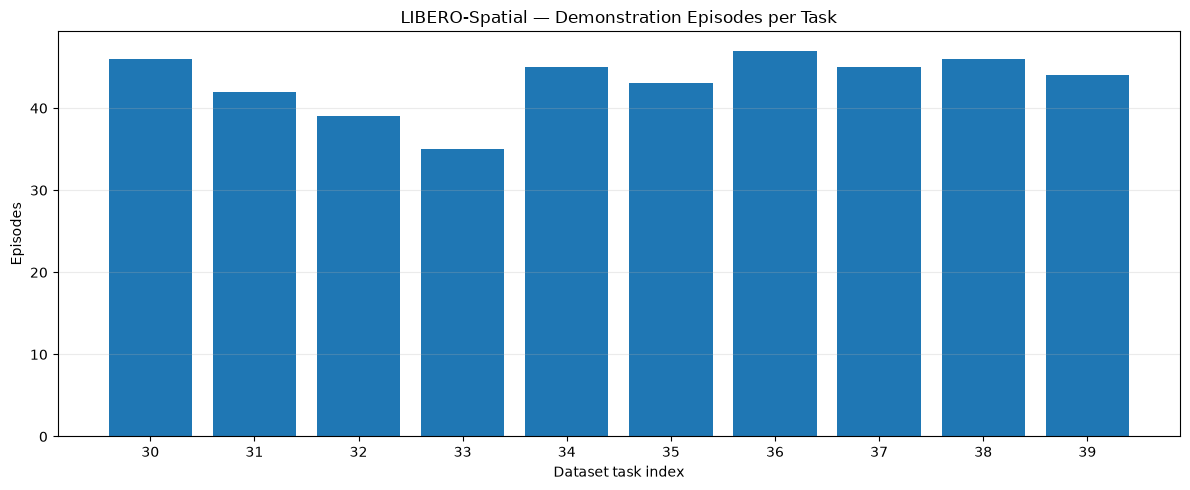

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    task_balance_df["task_index"].astype(str),
    task_balance_df["n_episodes"],
)
ax.set_title("LIBERO-Spatial — Demonstration Episodes per Task")
ax.set_xlabel("Dataset task index")
ax.set_ylabel("Episodes")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "episodes_per_task.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

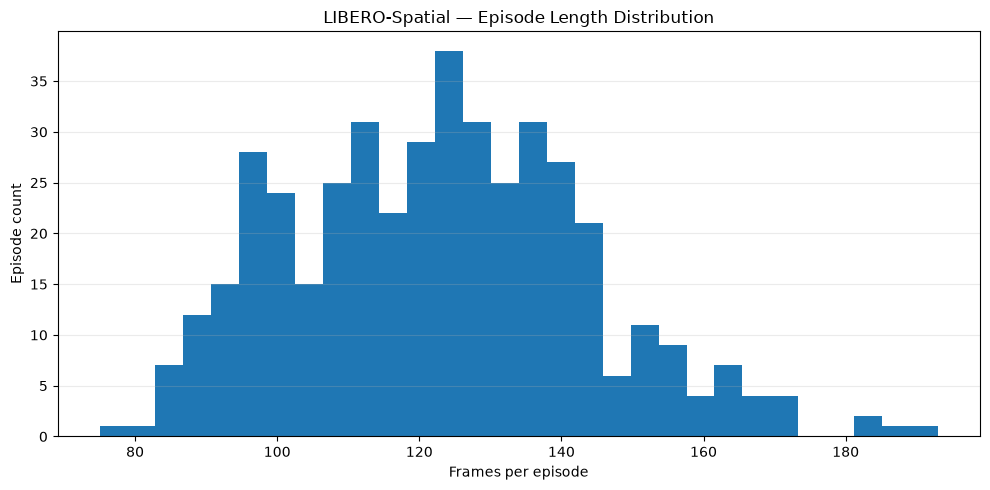

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(episode_df["n_frames"], bins=30)
ax.set_title("LIBERO-Spatial — Episode Length Distribution")
ax.set_xlabel("Frames per episode")
ax.set_ylabel("Episode count")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "episode_length_distribution.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### Why trajectory length matters

Equal episode counts do not necessarily imply equal training contribution.

A task with longer demonstrations contributes more training timesteps than a task with short demonstrations, so both **episode balance** and **frame balance** are retained for later training decisions.

## 9. Representative trajectory visualization

One episode is sampled at approximately:

`0% → 25% → 50% → 75% → 100%`

for both cameras.

This verifies that:

- frames decode correctly,
- the scene is visible,
- the trajectory progresses through time,
- both camera views contain useful visual information.

In [32]:
camera_keys = list(spatial_dataset.meta.camera_keys)
assert len(camera_keys) >= 2, "Expected two camera streams for LIBERO."

target_dataset_task_index = int(
    task_match_df.loc[
        task_match_df["suite_task_id"] == TASK_ID_FOR_VISUALIZATION,
        "dataset_task_index",
    ].iloc[0]
)

candidate_eps = (
    episode_df.loc[
        episode_df["task_index"] == target_dataset_task_index,
        "episode_index",
    ]
    .sort_values()
    .astype(int)
    .tolist()
)

assert candidate_eps, "No episode available for the selected visualization task."

selected_episode_id = candidate_eps[
    min(EPISODE_POSITION_FOR_VISUALIZATION, len(candidate_eps) - 1)
]

row_positions = np.flatnonzero(episode_index == selected_episode_id)
sample_positions = np.linspace(
    row_positions[0],
    row_positions[-1],
    N_TRAJECTORY_FRAMES_TO_SHOW,
).round().astype(int)

print(f"Suite task ID      : {TASK_ID_FOR_VISUALIZATION}")
print(f"Dataset task index : {target_dataset_task_index}")
print(f"Episode index      : {selected_episode_id}")
print(f"Instruction        : {dataset_task_map[target_dataset_task_index]}")
print(f"Episode frames     : {len(row_positions)}")

Suite task ID      : 0
Dataset task index : 34
Episode index      : 1272
Instruction        : pick up the black bowl between the plate and the ramekin and place it on the plate
Episode frames     : 84


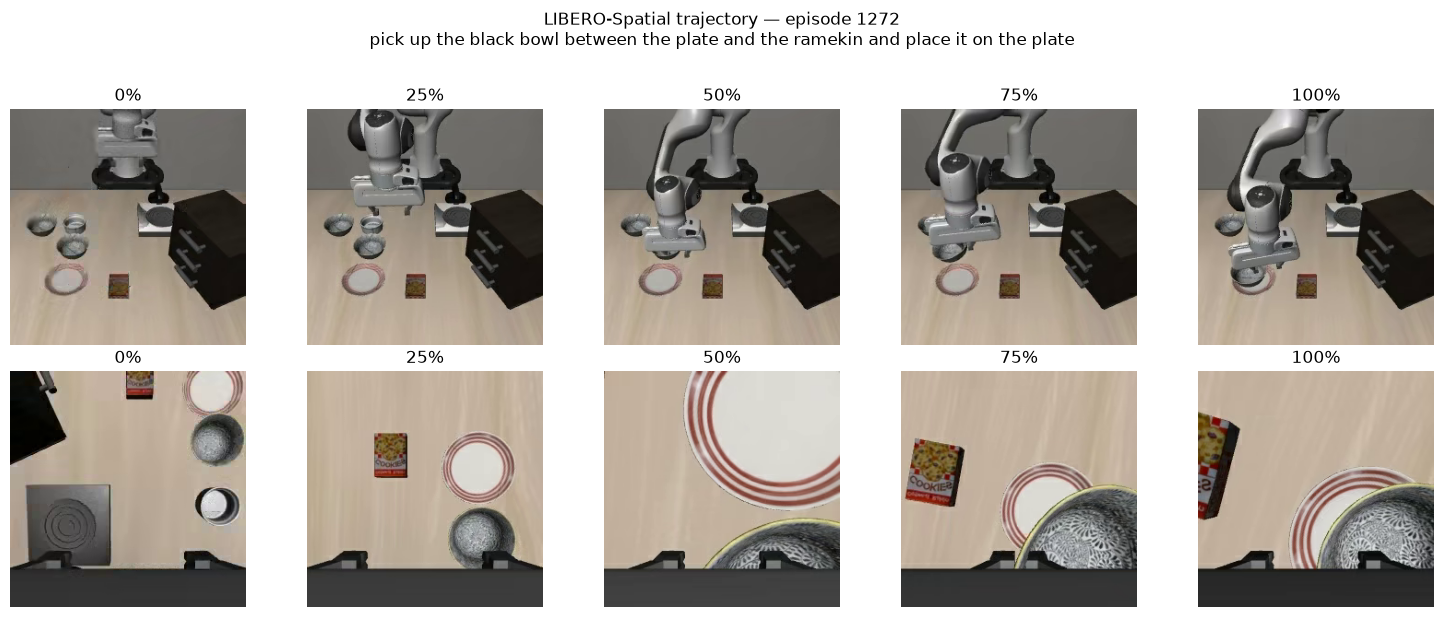

In [33]:
def tensor_image_to_hwc_uint8(img):
    """Convert a LeRobot tensor image to displayable HWC uint8."""
    if isinstance(img, torch.Tensor):
        arr = img.detach().cpu().numpy()
    else:
        arr = np.asarray(img)

    if arr.ndim == 3 and arr.shape[0] in (1, 3, 4):
        arr = np.transpose(arr, (1, 2, 0))

    if arr.dtype != np.uint8:
        if np.nanmax(arr) <= 1.0 + 1e-6:
            arr = np.clip(arr * 255.0, 0, 255)
        arr = arr.astype(np.uint8)

    return arr

fig, axes = plt.subplots(
    len(camera_keys),
    len(sample_positions),
    figsize=(3.0 * len(sample_positions), 3.0 * len(camera_keys)),
)

if len(camera_keys) == 1:
    axes = np.expand_dims(axes, axis=0)

for camera_row, camera_key in enumerate(camera_keys):
    for col, dataset_position in enumerate(sample_positions):
        sample = spatial_dataset[int(dataset_position)]
        image = tensor_image_to_hwc_uint8(sample[camera_key])

        axes[camera_row, col].imshow(image)
        axes[camera_row, col].axis("off")

        pct = int(round(100 * col / max(1, len(sample_positions) - 1)))
        axes[camera_row, col].set_title(f"{pct}%")

    axes[camera_row, 0].set_ylabel(camera_key, fontsize=9)

fig.suptitle(
    f"LIBERO-Spatial trajectory — episode {selected_episode_id}\n"
    f"{dataset_task_map[target_dataset_task_index]}",
    y=1.02,
)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "representative_trajectory_cameras.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 10. Action-space EDA

LIBERO exposes a 7-dimensional continuous action: six dimensions for end-effector control and one for the gripper.

This section measures the actual demonstration distribution to identify:

- saturation,
- near-zero channels,
- asymmetry,
- discrete-like gripper behaviour.

In [34]:
actions = np.asarray(spatial_hf["action"], dtype=np.float32)

assert actions.ndim == 2, f"Unexpected action shape: {actions.shape}"
assert actions.shape[1] == 7, f"Expected 7 action dimensions, got {actions.shape[1]}"

action_names = [
    "eef_delta_0",
    "eef_delta_1",
    "eef_delta_2",
    "eef_delta_3",
    "eef_delta_4",
    "eef_delta_5",
    "gripper",
]

action_stats_df = pd.DataFrame({
    "dimension": action_names,
    "min": np.nanmin(actions, axis=0),
    "p01": np.nanpercentile(actions, 1, axis=0),
    "p25": np.nanpercentile(actions, 25, axis=0),
    "median": np.nanmedian(actions, axis=0),
    "mean": np.nanmean(actions, axis=0),
    "p75": np.nanpercentile(actions, 75, axis=0),
    "p99": np.nanpercentile(actions, 99, axis=0),
    "max": np.nanmax(actions, axis=0),
    "std": np.nanstd(actions, axis=0),
})

display(action_stats_df)
action_stats_df.to_csv(
    METRICS_DIR / "action_statistics.csv",
    index=False
)

,dimension,min,p01,p25,median,mean,p75,p99,max,std
0,eef_delta_0,-0.9375,-0.745473,-0.091071,0.061607,0.153125,0.450000,0.937500,0.937500,0.412727
1,eef_delta_1,-0.9375,-0.661607,-0.029464,0.032143,0.137073,0.337500,0.875893,0.937500,0.347243
2,eef_delta_2,-0.9375,-0.937500,-0.605357,-0.085714,-0.155268,0.179464,0.932143,0.937500,0.508692
3,eef_delta_3,-0.1875,-0.107143,-0.020357,0.000000,-0.005176,0.000000,0.103929,0.197143,0.037266
4,eef_delta_4,-0.3675,-0.206786,-0.048214,0.000000,-0.011209,0.016071,0.176786,0.336429,0.072444
5,eef_delta_5,-0.3600,-0.184286,-0.047143,0.000000,-0.020194,-0.000000,0.145714,0.375000,0.057624
6,gripper,-1.0000,-1.000000,-1.000000,1.000000,0.084236,1.000000,1.000000,1.000000,0.996557


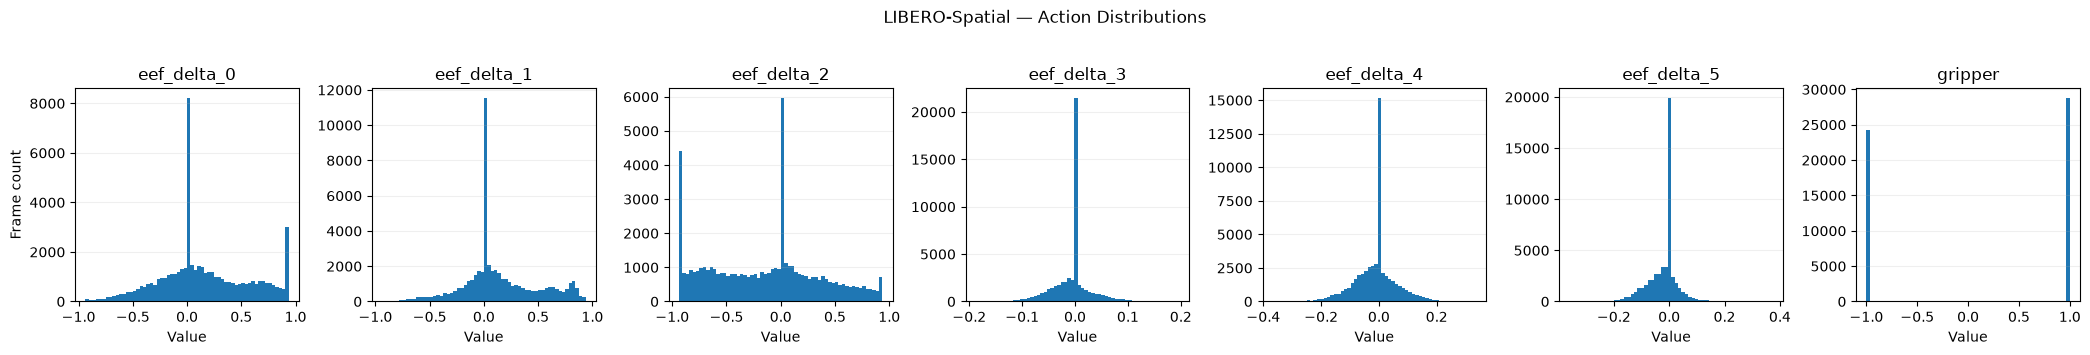

In [35]:
fig, axes = plt.subplots(1, actions.shape[1], figsize=(21, 3.4))

for i, ax in enumerate(axes):
    ax.hist(actions[:, i], bins=60)
    ax.set_title(action_names[i])
    ax.set_xlabel("Value")
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Frame count")
fig.suptitle("LIBERO-Spatial — Action Distributions", y=1.03)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "action_distributions.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [36]:
gripper = actions[:, -1]

gripper_summary = {
    "min": float(np.min(gripper)),
    "max": float(np.max(gripper)),
    "mean": float(np.mean(gripper)),
    "std": float(np.std(gripper)),
    "fraction_lt_-0.5": float(np.mean(gripper < -0.5)),
    "fraction_between_-0.5_0.5": float(
        np.mean((gripper >= -0.5) & (gripper <= 0.5))
    ),
    "fraction_gt_0.5": float(np.mean(gripper > 0.5)),
}

display(pd.DataFrame([gripper_summary]))

,min,max,mean,std,fraction_lt_-0.5,fraction_between_-0.5_0.5,fraction_gt_0.5
0,-1.0,1.0,0.084236,0.996446,0.457882,0.0,0.542118


## 11. Robot-state EDA

The LIBERO policy state is expected to contain 8 proprioceptive values. The exact dimensionality is verified from the pinned dataset before descriptive statistics are calculated.

In [37]:
states = np.asarray(
    spatial_hf["observation.state"],
    dtype=np.float32,
)

assert states.ndim == 2, f"Unexpected state shape: {states.shape}"

state_names = (
    [
        "eef_x", "eef_y", "eef_z",
        "eef_rot_0", "eef_rot_1", "eef_rot_2",
        "gripper_qpos_0", "gripper_qpos_1",
    ]
    if states.shape[1] == 8
    else [f"state_{i}" for i in range(states.shape[1])]
)

state_stats_df = pd.DataFrame({
    "dimension": state_names,
    "min": np.nanmin(states, axis=0),
    "p01": np.nanpercentile(states, 1, axis=0),
    "median": np.nanmedian(states, axis=0),
    "mean": np.nanmean(states, axis=0),
    "p99": np.nanpercentile(states, 99, axis=0),
    "max": np.nanmax(states, axis=0),
    "std": np.nanstd(states, axis=0),
})

display(state_stats_df)
state_stats_df.to_csv(
    METRICS_DIR / "state_statistics.csv",
    index=False
)

,dimension,min,p01,median,mean,p99,max,std
0,eef_x,-0.309547,-0.272766,0.014638,-0.024463,0.135294,0.175904,0.110148
1,eef_y,-0.292508,-0.237214,0.137636,0.106530,0.362916,0.390482,0.137847
2,eef_z,0.909559,0.916006,1.041783,1.058048,1.286233,1.329072,0.104428
3,eef_rot_0,2.497488,2.779497,3.084222,3.062847,3.282970,3.456612,0.104511
4,eef_rot_1,-1.800649,-1.318751,-0.015446,-0.104640,0.933276,1.226860,0.411210
5,eef_rot_2,-0.720761,-0.419900,0.056793,0.083073,0.632572,1.042941,0.217669
6,gripper_qpos_0,-0.000470,0.001504,0.010939,0.019955,0.039934,0.041054,0.017261
7,gripper_qpos_1,-0.041536,-0.039898,-0.011694,-0.020163,-0.001672,0.000776,0.017112


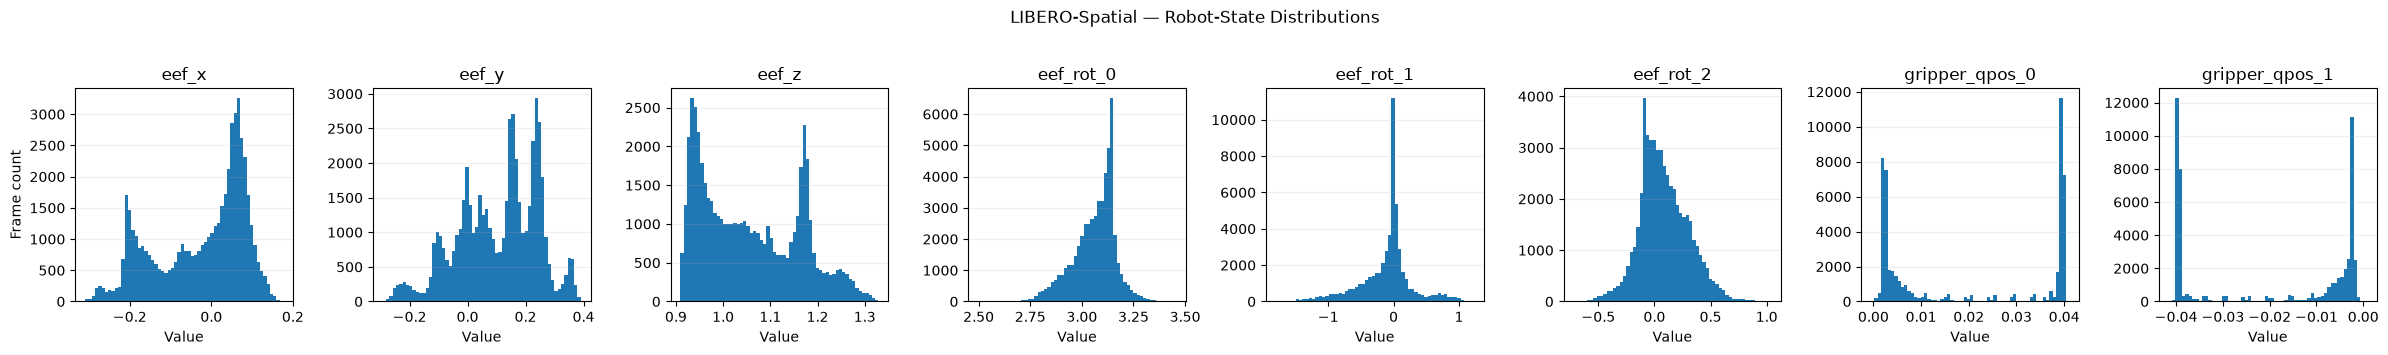

In [38]:
fig, axes = plt.subplots(
    1,
    states.shape[1],
    figsize=(3 * states.shape[1], 3.4),
)

if states.shape[1] == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.hist(states[:, i], bins=60)
    ax.set_title(state_names[i])
    ax.set_xlabel("Value")
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Frame count")
fig.suptitle("LIBERO-Spatial — Robot-State Distributions", y=1.03)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "state_distributions.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 12. Language EDA

Language is central to the proposed robustness study.

The original instructions are analysed before any paraphrases are created. Later robustness evaluation will use controlled levels:

- `L0` — original benchmark instruction,
- `L1` — lexical / synonym variation,
- `L2` — syntactic restructuring,
- `L3` — compositional rewording.

In [39]:
spatial_language_df = task_match_df[
    ["suite_task_id", "dataset_task_index", "benchmark_instruction"]
].copy()

def simple_tokens(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())

spatial_language_df["word_count"] = (
    spatial_language_df["benchmark_instruction"]
    .map(lambda x: len(simple_tokens(x)))
)
spatial_language_df["unique_word_count"] = (
    spatial_language_df["benchmark_instruction"]
    .map(lambda x: len(set(simple_tokens(x))))
)

display(spatial_language_df)
spatial_language_df.to_csv(
    METRICS_DIR / "language_summary.csv",
    index=False
)

all_tokens = [
    token
    for text in spatial_language_df["benchmark_instruction"]
    for token in simple_tokens(text)
]

token_counts = pd.DataFrame(
    Counter(all_tokens).most_common(),
    columns=["token", "count"],
)

display(token_counts.head(25))
token_counts.to_csv(
    METRICS_DIR / "language_token_counts.csv",
    index=False
)

,suite_task_id,dataset_task_index,benchmark_instruction,word_count,unique_word_count
0,0,34,pick up the black bowl between the plate and t...,17,12
1,1,37,pick up the black bowl next to the ramekin and...,15,13
2,2,38,pick up the black bowl from table center and p...,14,13
3,3,35,pick up the black bowl on the cookie box and p...,15,12
4,4,31,pick up the black bowl in the top drawer of th...,19,16
5,5,32,pick up the black bowl on the ramekin and plac...,14,11
6,6,30,pick up the black bowl next to the cookie box ...,16,14
7,7,33,pick up the black bowl on the stove and place ...,14,11
8,8,36,pick up the black bowl next to the plate and p...,15,12
9,9,39,pick up the black bowl on the wooden cabinet a...,15,12


,token,count
0,the,31
1,on,14
2,plate,12
3,and,11
4,pick,10
5,up,10
6,black,10
7,bowl,10
8,place,10
9,it,10


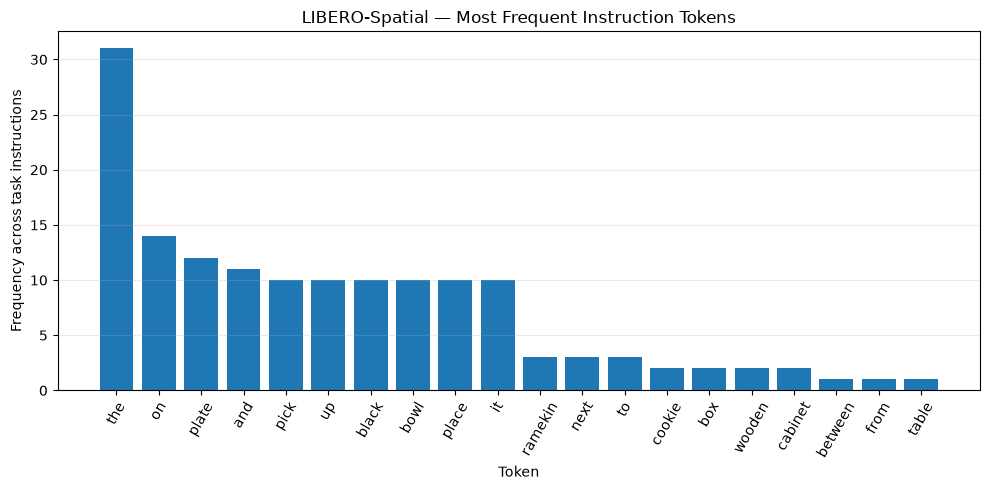

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
top_tokens = token_counts.head(20)
ax.bar(top_tokens["token"], top_tokens["count"])
ax.set_title("LIBERO-Spatial — Most Frequent Instruction Tokens")
ax.set_xlabel("Token")
ax.set_ylabel("Frequency across task instructions")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "language_top_tokens.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 13. Dataset integrity audit

The audit checks numerical and sequential properties that could invalidate later experiments.

Adjacent visual frames are expected to be similar inside a trajectory, so temporal similarity is **not** incorrectly treated as duplicate-sample leakage.

In [41]:
audit = {
    "dataset_revision_resolved": bool(DATASET_REVISION),
    "spatial_tasks_expected_10": len(SPATIAL_DATASET_TASK_INDICES) == 10,
    "spatial_episodes_positive": len(episode_df) > 0,
    "all_episodes_single_task": bool(
        (episode_df["n_unique_task_indices"] == 1).all()
    ),
    "all_frame_indices_contiguous": bool(
        episode_df["frame_index_contiguous"].all()
    ),
    "all_timestamps_monotonic": bool(
        episode_df["timestamp_monotonic"].all()
    ),
    "actions_shape_7": actions.shape[1] == 7,
    "actions_all_finite": bool(np.isfinite(actions).all()),
    "states_all_finite": bool(np.isfinite(states).all()),
    "no_zero_length_episodes": bool((episode_df["n_frames"] > 0).all()),
    "all_tasks_have_episodes": bool(
        (task_balance_df["n_episodes"] > 0).all()
    ),
}

audit_df = pd.DataFrame(
    [{"check": key, "pass": value}
     for key, value in audit.items()]
)

display(audit_df)

AUDIT_PASS = bool(audit_df["pass"].all())
print("\nDATASET AUDIT:", "PASS" if AUDIT_PASS else "REVIEW REQUIRED")

audit_df.to_csv(
    METRICS_DIR / "dataset_integrity_audit.csv",
    index=False
)

with open(METRICS_DIR / "dataset_integrity_audit.json", "w") as f:
    json.dump(
        {"audit_pass": AUDIT_PASS, **audit},
        f,
        indent=2,
    )

,check,pass
0,dataset_revision_resolved,True
1,spatial_tasks_expected_10,True
2,spatial_episodes_positive,True
3,all_episodes_single_task,True
4,all_frame_indices_contiguous,True
5,all_timestamps_monotonic,True
6,actions_shape_7,True
7,actions_all_finite,True
8,states_all_finite,True
9,no_zero_length_episodes,True



DATASET AUDIT: PASS


## 14. Candidate train / validation split

### Split principle

The demonstrations are split by **whole episode**, stratified by task.

For each LIBERO-Spatial task:

- approximately 80% of episodes → training,
- approximately 20% → validation,
- seed `42` → deterministic reproduction.

The final test remains **closed-loop simulator evaluation** under the project's E0/E1/E2/E3 conditions.

The output is named `candidate` so that the distribution can be reviewed before promotion to Data Split v1.0.

In [42]:
rng = np.random.default_rng(SEED)
split_rows = []

for task_idx, group in episode_df.groupby("task_index", sort=True):
    episode_ids = np.array(
        sorted(group["episode_index"].astype(int).tolist())
    )
    shuffled = episode_ids.copy()
    rng.shuffle(shuffled)

    n_total = len(shuffled)
    n_val = max(
        1,
        int(round(n_total * VALIDATION_FRACTION)),
    )

    if n_total > 1:
        n_val = min(n_val, n_total - 1)

    val_ids_for_task = set(shuffled[:n_val].tolist())

    frame_lookup = (
        group.set_index("episode_index")["n_frames"].to_dict()
    )

    for ep in episode_ids:
        split_rows.append({
            "episode_index": int(ep),
            "task_index": int(task_idx),
            "task_instruction": dataset_task_map[int(task_idx)],
            "n_frames": int(frame_lookup[int(ep)]),
            "split": "validation"
                if int(ep) in val_ids_for_task
                else "train",
            "split_seed": SEED,
            "validation_fraction_target": VALIDATION_FRACTION,
            "dataset_repo_id": DATASET_REPO_ID,
            "dataset_revision": DATASET_REVISION,
        })

split_df = (
    pd.DataFrame(split_rows)
    .sort_values(["task_index", "episode_index"])
    .reset_index(drop=True)
)

display(split_df.head(20))

,episode_index,task_index,task_instruction,n_frames,split,split_seed,validation_fraction_target,dataset_repo_id,dataset_revision
0,1261,30,pick up the black bowl next to the cookie box ...,110,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
1,1274,30,pick up the black bowl next to the cookie box ...,113,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
2,1277,30,pick up the black bowl next to the cookie box ...,111,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
3,1291,30,pick up the black bowl next to the cookie box ...,125,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
4,1292,30,pick up the black bowl next to the cookie box ...,157,validation,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
5,1301,30,pick up the black bowl next to the cookie box ...,141,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
6,1304,30,pick up the black bowl next to the cookie box ...,113,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
7,1309,30,pick up the black bowl next to the cookie box ...,115,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
8,1314,30,pick up the black bowl next to the cookie box ...,117,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
9,1329,30,pick up the black bowl next to the cookie box ...,124,train,42,0.2,lerobot/libero,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4


In [43]:
split_summary_df = (
    split_df.groupby(["task_index", "split"], as_index=False)
    .agg(
        episodes=("episode_index", "nunique"),
        frames=("n_frames", "sum"),
    )
)

display(split_summary_df)

train_ids = set(
    split_df.loc[
        split_df["split"] == "train",
        "episode_index",
    ]
)
val_ids = set(
    split_df.loc[
        split_df["split"] == "validation",
        "episode_index",
    ]
)

split_checks = {
    "episode_sets_disjoint": train_ids.isdisjoint(val_ids),
    "all_episodes_assigned_once":
        len(split_df) == split_df["episode_index"].nunique(),
    "train_nonempty": len(train_ids) > 0,
    "validation_nonempty": len(val_ids) > 0,
    "all_tasks_in_train":
        split_df.loc[
            split_df["split"] == "train",
            "task_index",
        ].nunique() == 10,
    "all_tasks_in_validation":
        split_df.loc[
            split_df["split"] == "validation",
            "task_index",
        ].nunique() == 10,
}

split_checks_df = pd.DataFrame(
    [{"check": key, "pass": value}
     for key, value in split_checks.items()]
)
display(split_checks_df)

assert split_checks_df["pass"].all(), (
    "Candidate split failed one or more leakage/balance checks."
)

candidate_split_path = (
    SPLITS_DIR /
    f"libero_spatial_split_candidate_seed{SEED}.csv"
)
split_df.to_csv(candidate_split_path, index=False)

print(f"Candidate split saved to:\n{candidate_split_path}")

,task_index,split,episodes,frames
0,30,train,37,4614
1,30,validation,9,1161
2,31,train,34,5042
3,31,validation,8,1215
4,32,train,31,3544
5,32,validation,8,928
6,33,train,28,3785
7,33,validation,7,962
8,34,train,36,3567
9,34,validation,9,920


,check,pass
0,episode_sets_disjoint,True
1,all_episodes_assigned_once,True
2,train_nonempty,True
3,validation_nonempty,True
4,all_tasks_in_train,True
5,all_tasks_in_validation,True


Candidate split saved to:
/home/leeming/projects/deep-learning-vla-robustness/configs/splits/libero_spatial_split_candidate_seed42.csv


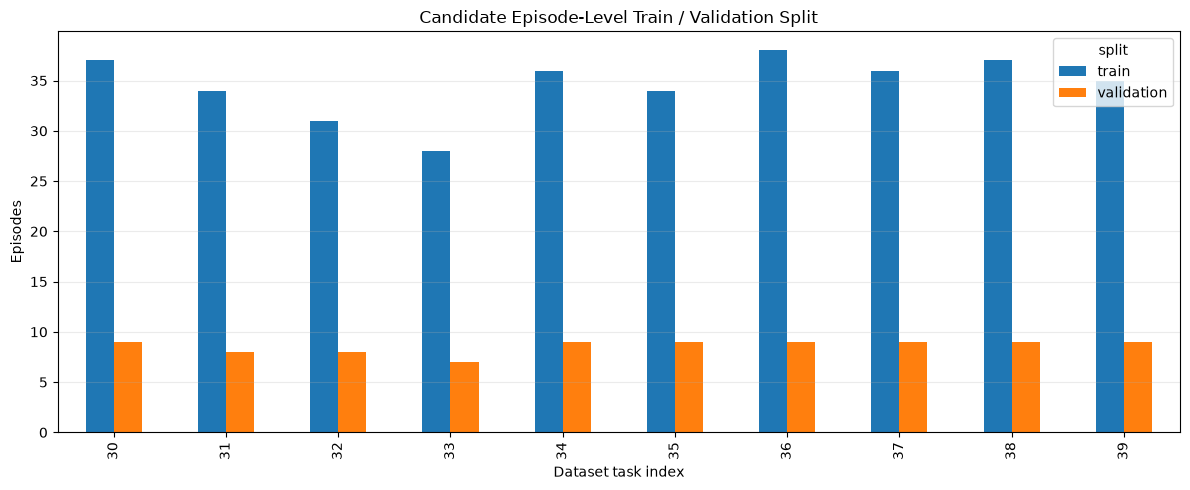

In [44]:
plot_df = (
    split_df.groupby(["task_index", "split"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
plot_df.plot(kind="bar", ax=ax)
ax.set_title("Candidate Episode-Level Train / Validation Split")
ax.set_xlabel("Dataset task index")
ax.set_ylabel("Episodes")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "candidate_train_validation_split.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 15. Live simulator sanity check

The demonstration dataset and simulator are separate components.

This section confirms that a LIBERO-Spatial task can be instantiated using a fixed benchmark initial state, returns both RGB camera observations and accepts a 7-dimensional control action.

This is a **technical compatibility check**, not a model-performance result.

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets
Task: pick up the black bowl between the plate and the ramekin and place it on the plate
Agent-view shape: (128, 128, 3) uint8
Eye-in-hand shape: (128, 128, 3) uint8


,task_id,init_state_id,agentview_shape,eye_in_hand_shape,action_dim,reward_after_zero_action,done_after_zero_action,simulator_step
0,0,0,"[128, 128, 3]","[128, 128, 3]",7,0.0,False,PASS


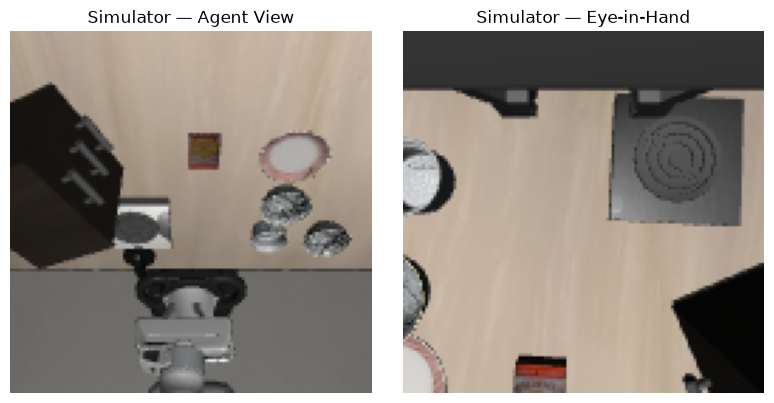

In [ ]:
from libero.libero import get_libero_path
from libero.libero.envs import OffScreenRenderEnv

SIM_TASK_ID = 0
SIM_INIT_STATE_ID = 0

sim_task = spatial_suite.get_task(SIM_TASK_ID)

bddl_path = os.path.join(
    get_libero_path("bddl_files"),
    sim_task.problem_folder,
    sim_task.bddl_file,
)

env_args = {
    "bddl_file_name": bddl_path,
    "camera_heights": 128,
    "camera_widths": 128,
}

env = None

try:
    # --------------------------------------------------
    # Create and initialize LIBERO simulator
    # --------------------------------------------------
    env = OffScreenRenderEnv(**env_args)
    env.seed(SEED)

    obs = env.reset()

    init_states = spatial_suite.get_task_init_states(
        SIM_TASK_ID
    )

    obs = env.set_init_state(
        init_states[SIM_INIT_STATE_ID]
    )

    # --------------------------------------------------
    # Extract RAW simulator observations
    #
    # Important:
    # Keep these raw arrays unchanged.
    # The vertical flip below is ONLY for visualization.
    # Model preprocessing will be handled separately
    # in Notebook 01.
    # --------------------------------------------------
    agent = obs["agentview_image"]
    wrist = obs["robot0_eye_in_hand_image"]

    print("Task:", sim_task.language)
    print(
        "Agent-view shape:",
        agent.shape,
        agent.dtype,
    )
    print(
        "Eye-in-hand shape:",
        wrist.shape,
        wrist.dtype,
    )

    # --------------------------------------------------
    # Basic simulator step sanity check
    # --------------------------------------------------
    zero_action = np.zeros(
        7,
        dtype=np.float32,
    )

    next_obs, reward, done, info = env.step(
        zero_action
    )

    simulator_summary = {
        "task_id": SIM_TASK_ID,
        "init_state_id": SIM_INIT_STATE_ID,
        "agentview_shape": list(agent.shape),
        "eye_in_hand_shape": list(wrist.shape),
        "action_dim": int(
            zero_action.shape[0]
        ),
        "reward_after_zero_action": float(
            reward
        ),
        "done_after_zero_action": bool(
            done
        ),
        "simulator_step": "PASS",
    }

    display(
        pd.DataFrame(
            [simulator_summary]
        )
    )

    # --------------------------------------------------
    # Visualization only
    #
    # MuJoCo / OpenGL rendered image buffers can use an
    # origin convention opposite to matplotlib's expected
    # image orientation.
    #
    # Therefore we vertically flip the images ONLY for
    # human-readable plotting.
    # --------------------------------------------------
    agent_display = np.flipud(agent)
    wrist_display = np.flipud(wrist)

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(8, 4),
    )

    axes[0].imshow(agent_display)
    axes[0].set_title(
        "Simulator — Agent View"
    )
    axes[0].axis("off")

    axes[1].imshow(wrist_display)
    axes[1].set_title(
        "Simulator — Eye-in-Hand"
    )
    axes[1].axis("off")

    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR
        / "simulator_camera_sanity.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

finally:
    if env is not None:
        env.close()

## 16. Consolidated EDA summary

No model-performance conclusion is drawn in Notebook 00.

The objective is to establish that:

- the environment is valid,
- dataset provenance is pinned,
- LIBERO-Spatial tasks are correctly identified,
- demonstration trajectories are understood,
- action/state/language distributions have been inspected,
- integrity checks pass,
- train/validation separation occurs at episode level.

In [46]:
summary = {
    "notebook": "00_environment_and_dataset_eda.ipynb",
    "seed": SEED,
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "suite": LIBERO_SUITE,
    "n_spatial_tasks": int(len(SPATIAL_DATASET_TASK_INDICES)),
    "spatial_dataset_task_indices":
        [int(x) for x in SPATIAL_DATASET_TASK_INDICES],
    "n_spatial_episodes": int(len(episode_df)),
    "n_spatial_frames": int(spatial_dataset.num_frames),
    "mean_episode_frames": float(episode_df["n_frames"].mean()),
    "median_episode_frames": float(episode_df["n_frames"].median()),
    "min_episode_frames": int(episode_df["n_frames"].min()),
    "max_episode_frames": int(episode_df["n_frames"].max()),
    "action_dimension": int(actions.shape[1]),
    "state_dimension": int(states.shape[1]),
    "camera_keys": list(spatial_dataset.meta.camera_keys),
    "dataset_audit_pass": bool(AUDIT_PASS),
    "candidate_split_seed": SEED,
    "candidate_validation_fraction": VALIDATION_FRACTION,
    "n_train_episodes": int(len(train_ids)),
    "n_validation_episodes": int(len(val_ids)),
    "candidate_split_path":
        str(candidate_split_path.relative_to(REPO_ROOT)),
    "project_git_sha": project_git_sha,
    "lerobot_git_sha": lerobot_git_sha,
}

summary_df = (
    pd.DataFrame([summary])
    .T
    .rename(columns={0: "Value"})
)
display(summary_df)

with open(METRICS_DIR / "dataset_eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nNotebook 00 summary saved successfully.")

,Value
notebook,00_environment_and_dataset_eda.ipynb
seed,42
dataset_repo_id,lerobot/libero
dataset_revision,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
suite,libero_spatial
n_spatial_tasks,10
spatial_dataset_task_indices,"[30, 31, 32, 33, 34, 35, 36, 37, 38, 39]"
n_spatial_episodes,432
n_spatial_frames,52970
mean_episode_frames,122.615741



Notebook 00 summary saved successfully.


## 17. Review checklist

Before freezing the split:

- [ ] Dataset revision SHA is recorded.
- [ ] Exactly 10 LIBERO-Spatial tasks are mapped with high confidence.
- [ ] Episode counts per task are reasonable.
- [ ] Frame counts do not reveal severe imbalance.
- [ ] Representative trajectory images are valid.
- [ ] No NaN / infinite actions or states.
- [ ] Episode frame indices are contiguous.
- [ ] Episode timestamps are monotonic.
- [ ] Action distributions are plausible.
- [ ] Gripper distribution is understood.
- [ ] Language distribution is documented.
- [ ] Train and validation episode sets are disjoint.
- [ ] Every task appears in both train and validation.
- [ ] Simulator sanity check passes.

If the audit is satisfactory, promote the candidate split to formal **Data Split v1.0** before tuning.

---

## Next notebook

`01_smolvla_baseline_reproduction.ipynb`

Planned scope:

1. load the released LIBERO-fine-tuned SmolVLA checkpoint;
2. pin the checkpoint revision;
3. inspect model input/output configuration;
4. validate preprocessing;
5. perform inference;
6. execute model-generated actions in LIBERO;
7. complete a policy-controlled episode;
8. close Technical Compatibility Gate G0;
9. begin M0 baseline reproduction.

## Technical references

- Hugging Face LeRobot — LIBERO  
  https://huggingface.co/docs/lerobot/main/libero

- Hugging Face LeRobot dataset API  
  https://huggingface.co/docs/lerobot/main/api/datasets

- LeRobot LIBERO dataset  
  https://huggingface.co/datasets/lerobot/libero

- LIBERO benchmark  
  https://github.com/Lifelong-Robot-Learning/LIBERO

- Liu, B., Zhu, Y., Gao, C., Feng, Y., Liu, Q., Zhu, Y., & Stone, P. (2023).  
  *LIBERO: Benchmarking Knowledge Transfer for Lifelong Robot Learning.*  
  https://arxiv.org/abs/2306.03310